# 02 — Baselines et régression logistique

**Objectif** : mesurer ce qu'on obtient sans modèle, puis avec une régression logistique, et savoir lire ses coefficients.

Questions traitées :
1. Quelle performance obtient-on sans aucun modèle (baselines) ?
2. Que gagne une régression logistique sur les 82 variables de base ?
3. Comment lire ses coefficients (odds ratios) ?
4. Un petit modèle lisible, à la manière des grilles de score des banques, fait-il presque aussi bien ?

**Règle suivie** : le jeu de test n'est **pas** chargé. Tous les modèles sont comparés par **validation croisée** sur le jeu d'apprentissage.
Les nouvelles variables (ratios, agrégats de `bureau.csv`) sont gardées pour l'étape 7 : ici, seulement les variables de base.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

sys.path.insert(0, "..")  # pour importer src/
from src.prepare_data import COLONNES_HORS_MODELE, VARIABLES_NOUVELLES

pd.set_option("display.max_columns", 60)

# Couleurs : une par modèle, toujours la même d'un graphique à l'autre
BLEU, ORANGE, VERT_D_EAU = "#2a78d6", "#eb6834", "#1baf7a"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})

## 1. Données et variables de base

In [2]:
DOSSIER_PROCESSED = Path("..") / "data" / "processed"
train = pd.read_parquet(DOSSIER_PROCESSED / "train.parquet")
y = train["TARGET"].to_numpy()

variables = [c for c in train.columns if c not in COLONNES_HORS_MODELE + VARIABLES_NOUVELLES]
categorielles = [c for c in variables if not pd.api.types.is_numeric_dtype(train[c])]
numeriques = [c for c in variables if c not in categorielles]
X = train[variables]

print(f"{len(train):,} prêts d'apprentissage, taux de défaut {y.mean():.2%}")
print(f"{len(variables)} variables de base : {len(numeriques)} numériques et {len(categorielles)} catégorielles")
print("Hors modèle :", COLONNES_HORS_MODELE)

246,008 prêts d'apprentissage, taux de défaut 8.07%
82 variables de base : 69 numériques et 13 catégorielles
Hors modèle : ['SK_ID_CURR', 'TARGET', 'CODE_GENDER']


## 2. Méthode d'évaluation : validation croisée stratifiée en 5 plis

Le jeu d'apprentissage est coupé en 5 parts (« plis ») qui gardent chacune 8,1 % de défauts.
Chaque modèle est entraîné 5 fois sur 4 plis et prédit le pli restant. À la fin :
- **chaque client a une prédiction faite par un modèle qui ne l'a pas vu** (prédiction *out-of-fold*) ;
- on calcule l'AUC sur chacun des 5 plis : la **moyenne** mesure la performance, l'**écart-type** sa stabilité.

Les prédictions *out-of-fold* servent aussi à tracer les courbes et, plus tard, à choisir le seuil de décision
sans jamais toucher au jeu de test.

**Rappel des métriques** :
- **ROC AUC** : probabilité qu'un client en défaut ait un score de risque plus élevé qu'un bon client tiré au hasard (0,5 = hasard).
- **PR AUC** (précision moyenne) : qualité du modèle sur la classe rare. Un modèle au hasard obtient la part de défauts, soit **0,081**.

In [3]:
PLIS = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
INDICES_PLIS = [validation for _, validation in PLIS.split(X, y)]
resultats = []


def evaluer(nom, score, nb_variables):
    """ROC AUC et PR AUC sur chacun des 5 plis (score : plus il est élevé, plus le risque est grand)."""
    roc = [roc_auc_score(y[i], score[i]) for i in INDICES_PLIS]
    pr = [average_precision_score(y[i], score[i]) for i in INDICES_PLIS]
    resultats.append({"modele": nom, "variables": nb_variables, "roc_auc": np.mean(roc),
                      "ecart_type": np.std(roc), "pr_auc": np.mean(pr)})
    print(f"{nom} : ROC AUC {np.mean(roc):.3f} ± {np.std(roc):.3f}, PR AUC {np.mean(pr):.3f}")


def predire_oof(modele, donnees):
    """Probabilité de défaut out-of-fold : chaque client est prédit par le modèle qui ne l'a pas vu."""
    return cross_val_predict(modele, donnees, y, cv=PLIS, method="predict_proba", n_jobs=5)[:, 1]


def tableau_resultats():
    return (pd.DataFrame(resultats).set_index("modele")
            .style.format({"variables": "{:,.0f}", "roc_auc": "{:.3f}", "ecart_type": "{:.3f}", "pr_auc": "{:.3f}"}))

## 3. Baselines

### 3.1 « Personne ne fait défaut »

Le même score pour tout le monde : le modèle ne classe personne.

In [4]:
evaluer("Baseline : personne ne fait défaut", np.zeros(len(y)), 0)

Baseline : personne ne fait défaut : ROC AUC 0.500 ± 0.000, PR AUC 0.081


### 3.2 La moyenne des scores externes, sans modèle

Le notebook 01 a montré que les trois scores externes `EXT_SOURCE_1` à `3` classent déjà bien les clients.
Baseline : leur **moyenne** (sur les scores disponibles), utilisée directement comme score. Un score externe élevé
signale un bon client, d'où le signe moins. Rien n'est appris : c'est ce que ferait une banque qui se contente
d'acheter ces scores.

In [5]:
moyenne_ext = train[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
print(f"Clients sans aucun score externe : {moyenne_ext.isna().sum()} (score neutre de 0,5)")
score_ext = -moyenne_ext.fillna(0.5).to_numpy()
evaluer("Baseline : moyenne des scores externes", score_ext, 3)

Clients sans aucun score externe : 139 (score neutre de 0,5)


Baseline : moyenne des scores externes : ROC AUC 0.716 ± 0.003, PR AUC 0.189


Sans aucun apprentissage, la moyenne des scores externes atteint déjà une **ROC AUC de 0,716**.
C'est la barre à battre : un modèle qui ne fait pas mieux n'apporte rien à la banque.

## 4. Régression logistique sur les 82 variables de base

### 4.1 Le modèle

La régression logistique prédit la probabilité de défaut :

$$p = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots + b_k x_k)}}$$

- La combinaison linéaire $b_0 + b_1 x_1 + \dots$ est le **log-odds** : $\ln\frac{p}{1-p}$.
  La fonction **sigmoïde** le transforme en probabilité entre 0 et 1.
- Les coefficients sont choisis pour minimiser la **log-loss**, qui punit fortement une probabilité confiante et fausse.
- scikit-learn ajoute une **pénalité L2** (comme Ridge dans le projet 1), d'intensité $1/C$ : plus $C$ est petit, plus les coefficients sont réduits.

### 4.2 La préparation des variables dans un `Pipeline`

Chaque étape qui apprend quelque chose des données (médiane, moyenne et écart-type, liste des modalités)
est placée **dans le pipeline**. Pendant la validation croisée, elle est donc réapprise sur les 4 plis d'entraînement
seulement : le pli de validation ne fuit jamais dans la préparation.

In [6]:
MONTANTS = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
autres_numeriques = [c for c in numeriques if c not in MONTANTS]


def regression_logistique(C=1.0):
    preparation = ColumnTransformer([
        # Montants très asymétriques (revenu jusqu'à 117 millions) : logarithme, puis standardisation
        ("montants", make_pipeline(SimpleImputer(strategy="median"),
                                   FunctionTransformer(np.log, feature_names_out="one-to-one"),
                                   StandardScaler()), MONTANTS),
        # Médiane + indicateur « valeur manquante » (l'absence est informative, notebook 01)
        ("numeriques", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                     StandardScaler()), autres_numeriques),
        # Une colonne 0/1 par modalité ; les modalités de moins de 100 prêts sont regroupées
        ("categorielles", make_pipeline(SimpleImputer(strategy="constant", fill_value="non renseigné"),
                                        OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist",
                                                      drop="if_binary", sparse_output=False)), categorielles),
    ], verbose_feature_names_out=False)
    return make_pipeline(preparation, LogisticRegression(C=C, max_iter=2000))


regression_logistique()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('montants', ...), ('numeriques', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

### 4.3 Choix de la régularisation $C$ par validation croisée

In [7]:
choix_c = []
for C in [0.001, 0.01, 0.1, 1]:
    debut = time.perf_counter()
    oof = predire_oof(regression_logistique(C), X)
    roc = [roc_auc_score(y[i], oof[i]) for i in INDICES_PLIS]
    choix_c.append({"C": C, "roc_auc": np.mean(roc), "ecart_type": np.std(roc),
                    "duree_s": time.perf_counter() - debut})
choix_c = pd.DataFrame(choix_c).set_index("C")
choix_c.style.format({"roc_auc": "{:.4f}", "ecart_type": "{:.4f}", "duree_s": "{:.0f}"}).format_index("{:g}")

,roc_auc,ecart_type,duree_s
C,,,
0.001,0.7446,0.0022,27
0.01,0.7468,0.0023,33
0.1,0.7471,0.0024,29
1,0.7470,0.0024,39


- L'AUC ne bouge presque pas (de 0,7446 à 0,7471) : comme dans le projet 1, avec **246 000 prêts pour 230 colonnes**,
  le modèle ne sur-apprend pas et la pénalité n'a presque rien à corriger.
- Seule une pénalité très forte ($C = 0{,}001$) dégrade un peu le modèle, en écrasant des coefficients utiles.
- On retient $C = 0{,}1$, la meilleure AUC moyenne.

In [8]:
C_RETENU = 0.1
oof_complete = predire_oof(regression_logistique(C_RETENU), X)
modele_complet = regression_logistique(C_RETENU).fit(X, y)
nb_colonnes = modele_complet[-1].coef_.shape[1]
print(f"{nb_colonnes} colonnes après préparation (indicateurs de valeurs manquantes et one-hot compris)")
evaluer("Régression logistique complète", oof_complete, len(variables))

230 colonnes après préparation (indicateurs de valeurs manquantes et one-hot compris)


Régression logistique complète : ROC AUC 0.747 ± 0.002, PR AUC 0.227


## 5. Lire les coefficients : les odds ratios

Toutes les variables numériques sont standardisées : chaque coefficient mesure l'effet de **+1 écart-type** sur le log-odds.
L'**odds ratio** $e^{b}$ dit par combien la **cote** de défaut $\frac{p}{1-p}$ est multipliée.
Avec un taux de défaut autour de 8 %, cote et probabilité sont proches : un odds ratio de 0,75 veut dire « environ 25 % de risque en moins ».

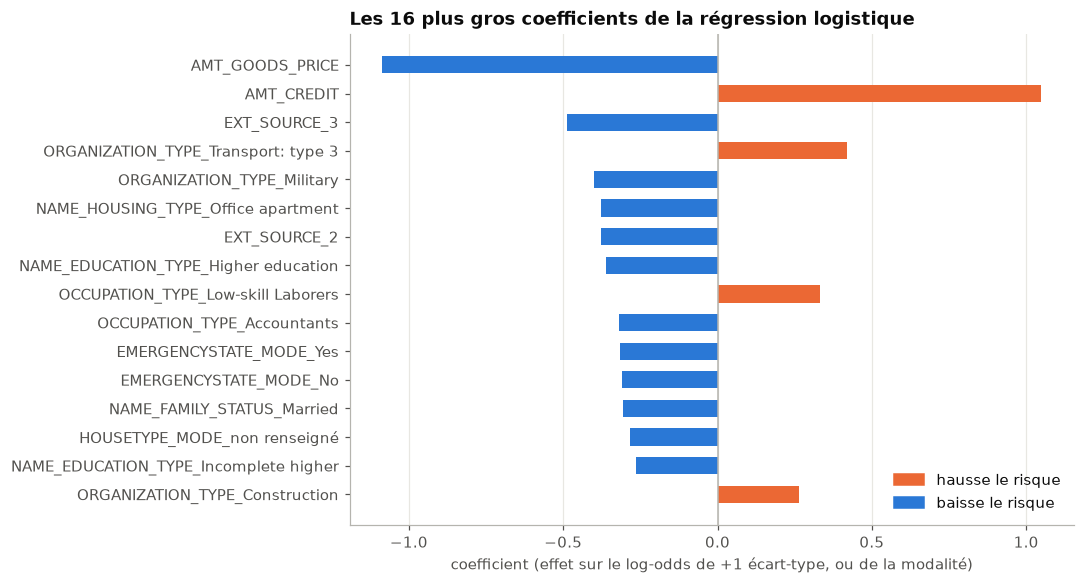

,coefficient,odds_ratio
AMT_GOODS_PRICE,-1.09,0.34
AMT_CREDIT,1.05,2.85
EXT_SOURCE_3,-0.49,0.61
ORGANIZATION_TYPE_Transport: type 3,0.42,1.52
ORGANIZATION_TYPE_Military,-0.40,0.67
NAME_HOUSING_TYPE_Office apartment,-0.38,0.68
EXT_SOURCE_2,-0.38,0.69
NAME_EDUCATION_TYPE_Higher education,-0.36,0.70
OCCUPATION_TYPE_Low-skill Laborers,0.33,1.39
OCCUPATION_TYPE_Accountants,-0.32,0.73


In [9]:
coefficients = pd.Series(modele_complet[-1].coef_[0], index=modele_complet[0].get_feature_names_out())
plus_forts = coefficients.reindex(coefficients.abs().sort_values().index).tail(16)

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.barh(plus_forts.index, plus_forts, color=[ORANGE if b > 0 else BLEU for b in plus_forts], height=0.6)
ax.axvline(0, color="#b5b4ae", linewidth=1)
ax.set_xlabel("coefficient (effet sur le log-odds de +1 écart-type, ou de la modalité)")
ax.set_title("Les 16 plus gros coefficients de la régression logistique", loc="left")
ax.legend(handles=[Patch(color=ORANGE, label="hausse le risque"), Patch(color=BLEU, label="baisse le risque")],
          loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
plt.show()

(pd.DataFrame({"coefficient": plus_forts[::-1], "odds_ratio": np.exp(plus_forts[::-1])})
 .style.format("{:.2f}"))

- **Les deux plus gros coefficients se compensent** : `AMT_CREDIT` (+1,05) et `AMT_GOODS_PRICE` (−1,09), corrélés à 0,99.
  Pris ensemble, ils disent : « à prix du bien égal, un crédit plus gros est plus risqué ». Le modèle reconstruit tout seul
  le ratio prix du bien / crédit repéré dans le notebook 01. Mais lus séparément, ces coefficients n'ont pas de sens.
- **Les scores externes** restent les variables numériques les plus fortes : +1 écart-type d'`EXT_SOURCE_3` multiplie la cote de défaut par 0,61.
- **Les modalités** se lisent mal : `EMERGENCYSTATE_MODE_Yes` et `_No` ont le même coefficient (−0,31). Ce qui compte, c'est
  d'avoir des informations sur l'immeuble (« Yes » ou « No ») plutôt que pas du tout (« non renseigné ») : encore une absence informative.
- **Conclusion** : un modèle à 230 colonnes prédit bien, mais ses coefficients sont difficiles à expliquer à un client.
  D'où le modèle lisible de la section suivante, et SHAP plus tard pour les modèles plus complexes.

## 6. Un modèle lisible à 15 variables, lu avec statsmodels

Pendant des décennies, les banques ont utilisé des **grilles de score** : une régression logistique sur une quinzaine de variables,
dont chaque effet se lit et se justifie auprès d'un client ou d'un régulateur. On en construit une, avec des variables
en **unités naturelles** (+0,1 de score, +10 ans, doublement d'un montant), pour lire les effets directement.

Les valeurs manquantes sont remplacées par des **valeurs fixes** (pas de médiane apprise), et un indicateur
« manquant » corrige l'effet de la valeur choisie : aucune statistique n'est apprise sur les données avant le modèle.

In [10]:
def variables_lisibles(donnees):
    """15 variables en unités naturelles, construites par des règles fixes."""
    lisibles = pd.DataFrame(index=donnees.index)
    for k in (1, 2, 3):
        score = donnees[f"EXT_SOURCE_{k}"]
        lisibles[f"EXT_SOURCE_{k} (+0,1)"] = score.fillna(0.5) * 10
        if k != 2:  # EXT_SOURCE_2 ne manque que pour 0,2 % des clients
            lisibles[f"EXT_SOURCE_{k} manquant"] = score.isna().astype(int)
    lisibles["AGE (+10 ans)"] = donnees["AGE"] / 10
    lisibles["ANCIENNETE_EMPLOI (+1 an)"] = donnees["ANCIENNETE_EMPLOI"].fillna(0)  # 0 si sans emploi
    lisibles["SANS_EMPLOI"] = donnees["SANS_EMPLOI"]
    lisibles["ETUDES_SUPERIEURES"] = donnees["NAME_EDUCATION_TYPE"].isin(
        ["Higher education", "Academic degree"]).astype(int)
    lisibles["NOTE_REGION (+1)"] = donnees["REGION_RATING_CLIENT_W_CITY"]
    lisibles["A_UNE_VOITURE"] = donnees["FLAG_OWN_CAR"]
    lisibles["CREDIT_RENOUVELABLE"] = (donnees["NAME_CONTRACT_TYPE"] == "Revolving loans").astype(int)
    credit = donnees["AMT_CREDIT"]
    lisibles["CREDIT (x2)"] = np.log2(credit)
    lisibles["ANNUITE (x2)"] = np.log2(donnees["AMT_ANNUITY"].fillna(credit / 20))  # 10 manquantes
    lisibles["PRIX_DU_BIEN (x2)"] = np.log2(donnees["AMT_GOODS_PRICE"].fillna(credit))  # 221 manquants
    return lisibles


X_lisible = variables_lisibles(train)


def vif(donnees):
    """VIF = 1 / (1 - R²) de chaque variable expliquée par toutes les autres."""
    avec_constante = sm.add_constant(donnees)
    return pd.Series([variance_inflation_factor(avec_constante.values, i) for i in range(1, avec_constante.shape[1])],
                     index=donnees.columns, name="VIF")


vif(X_lisible).sort_values(ascending=False).head(4).round(1).to_frame()

,VIF
PRIX_DU_BIEN (x2),53.8
CREDIT (x2),52.9
ANNUITE (x2),3.9
SANS_EMPLOI,2.2


**Colinéarité** : le montant du crédit et le prix du bien sont corrélés à 0,99 (notebook 01). Leurs VIF dépassent 50,
très au-delà du seuil de 10 : leurs coefficients seraient instables et illisibles (l'un très positif, l'autre très négatif).

**Solution sans perte d'information** : puisque $\log(\text{bien}) = \log(\text{crédit}) + \log(\frac{\text{bien}}{\text{crédit}})$,
on remplace le prix du bien par le **rapport bien / crédit**. Le modèle est *exactement* le même (mêmes prédictions),
mais chaque coefficient devient interprétable.

In [11]:
X_lisible_v2 = X_lisible.drop(columns="PRIX_DU_BIEN (x2)")
X_lisible_v2["BIEN / CREDIT (x2)"] = X_lisible["PRIX_DU_BIEN (x2)"] - X_lisible["CREDIT (x2)"]

logit_v1 = sm.Logit(y, sm.add_constant(X_lisible)).fit(disp=0)
logit_v2 = sm.Logit(y, sm.add_constant(X_lisible_v2)).fit(disp=0)
print(f"Log-vraisemblance : {logit_v1.llf:,.2f} (prix du bien) contre {logit_v2.llf:,.2f} (bien / crédit) : même modèle")
print(f"VIF maximal : {vif(X_lisible).max():.1f} → {vif(X_lisible_v2).max():.1f}")

Log-vraisemblance : -61,845.82 (prix du bien) contre -61,845.82 (bien / crédit) : même modèle


VIF maximal : 53.8 → 3.9


In [12]:
intervalles = np.exp(logit_v2.conf_int())
grille = pd.DataFrame({
    "coefficient": logit_v2.params,
    "odds_ratio": np.exp(logit_v2.params),
    "ic95_bas": intervalles[0],
    "ic95_haut": intervalles[1],
    "p_value": logit_v2.pvalues,
}).drop(index="const")
grille.style.format({"coefficient": "{:.3f}", "odds_ratio": "{:.2f}", "ic95_bas": "{:.2f}",
                     "ic95_haut": "{:.2f}", "p_value": "{:.3f}"})

,coefficient,odds_ratio,ic95_bas,ic95_haut,p_value
"EXT_SOURCE_1 (+0,1)",-0.167,0.85,0.84,0.86,0.000
EXT_SOURCE_1 manquant,0.310,1.36,1.32,1.41,0.000
"EXT_SOURCE_2 (+0,1)",-0.208,0.81,0.81,0.82,0.000
"EXT_SOURCE_3 (+0,1)",-0.284,0.75,0.75,0.76,0.000
EXT_SOURCE_3 manquant,0.196,1.22,1.17,1.26,0.000
AGE (+10 ans),-0.014,0.99,0.97,1.00,0.130
ANCIENNETE_EMPLOI (+1 an),-0.032,0.97,0.97,0.97,0.000
SANS_EMPLOI,-0.573,0.56,0.53,0.60,0.000
ETUDES_SUPERIEURES,-0.383,0.68,0.65,0.71,0.000
NOTE_REGION (+1),0.196,1.22,1.18,1.25,0.000


**Lecture de la grille** (toutes choses égales par ailleurs) :
- **Scores externes** : +0,1 sur `EXT_SOURCE_3` multiplie la cote de défaut par **0,75** (environ −25 % de risque).
  Un score `EXT_SOURCE_1` manquant la multiplie par **1,36**.
- **Emploi** : être sans emploi (retraité surtout) la multiplie par **0,56**, et chaque année d'ancienneté par 0,97.
- **Études supérieures** : × **0,68**. **Note de la région** : × 1,22 par point. **Voiture** : × 0,84.
- **Bien / crédit** : quand la part du crédit couverte par le bien double, la cote est multipliée par **0,32**.
  À rapport égal, doubler le montant du crédit ne change presque rien (× 0,91).
- **Annuité** : à crédit égal, une annuité deux fois plus élevée (donc un remboursement deux fois plus court) multiplie la cote par 1,28.
- **L'âge n'est plus significatif** (p = 0,13, intervalle de confiance qui contient 1), alors qu'il était très lié au défaut dans le notebook 01.
  Son effet passe déjà par `EXT_SOURCE_1` (corrélé à 0,60 avec l'âge) et par `SANS_EMPLOI` (les retraités).
  C'est la différence entre un lien **seul** et un effet **toutes choses égales par ailleurs**.

In [13]:
modele_lisible = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=2000))
oof_lisible = predire_oof(modele_lisible, X_lisible_v2)
evaluer("Régression logistique lisible", oof_lisible, X_lisible_v2.shape[1])

Régression logistique lisible : ROC AUC 0.740 ± 0.002, PR AUC 0.218


## 7. Courbes ROC et précision-rappel

Chaque point d'une courbe correspond à un **seuil** : on refuse les clients dont le score dépasse ce seuil.
- **Courbe ROC** : en abscisse, la part des bons clients refusés à tort ; en ordonnée, la part des défauts détectés.
  La diagonale correspond au hasard ; l'AUC est l'aire sous la courbe.
- **Courbe précision-rappel** : en abscisse, la part des défauts détectés (rappel) ; en ordonnée, la part de vrais défauts
  parmi les clients refusés (précision). Le hasard donne une précision de 8,1 %, quel que soit le seuil.

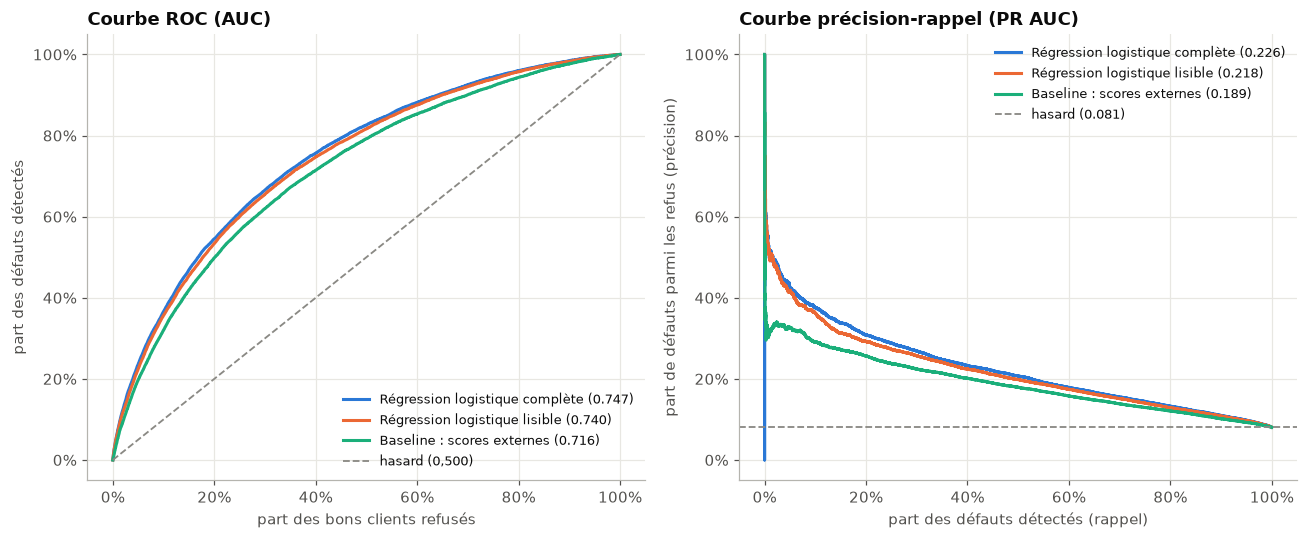

In [14]:
courbes = [("Régression logistique complète", oof_complete, BLEU),
           ("Régression logistique lisible", oof_lisible, ORANGE),
           ("Baseline : scores externes", score_ext, VERT_D_EAU)]

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
for nom, score, couleur in courbes:
    fpr, tpr, _ = roc_curve(y, score)
    ax_roc.plot(fpr, tpr, color=couleur, label=f"{nom} ({roc_auc_score(y, score):.3f})")
    precision, rappel, _ = precision_recall_curve(y, score)
    ax_pr.plot(rappel, precision, color=couleur, label=f"{nom} ({average_precision_score(y, score):.3f})")
ax_roc.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.2, label="hasard (0,500)")
ax_pr.axhline(y.mean(), color=GRIS, linestyle="--", linewidth=1.2, label=f"hasard ({y.mean():.3f})")

ax_roc.set_xlabel("part des bons clients refusés")
ax_roc.set_ylabel("part des défauts détectés")
ax_roc.set_title("Courbe ROC (AUC)", loc="left")
ax_pr.set_xlabel("part des défauts détectés (rappel)")
ax_pr.set_ylabel("part de défauts parmi les refus (précision)")
ax_pr.set_title("Courbe précision-rappel (PR AUC)", loc="left")
for ax in (ax_roc, ax_pr):
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(frameon=False, fontsize=8.5, loc="lower right" if ax is ax_roc else "upper right")
plt.tight_layout()
plt.show()

- Les trois courbes ROC sont proches : la logistique complète domine partout, mais de peu.
- La courbe précision-rappel montre la difficulté du problème : pour détecter la moitié des défauts,
  il faut accepter qu'environ 4 refus sur 5 concernent de bons clients.

## 8. Ce que le score permet déjà : concentrer les défauts

On range les clients en 10 groupes de taille égale selon leur probabilité de défaut prédite (out-of-fold).

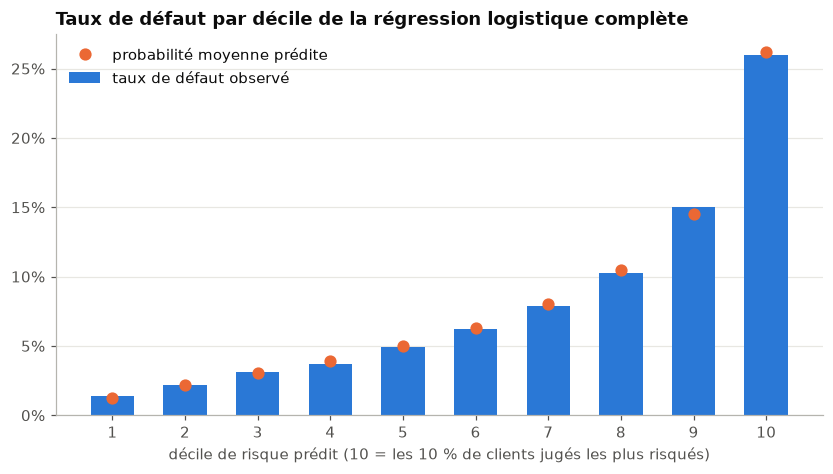

Les 10% de clients les plus risqués regroupent 32% des défauts
Les 20% de clients les plus risqués regroupent 51% des défauts
Les 30% de clients les plus risqués regroupent 64% des défauts


In [15]:
deciles = pd.qcut(oof_complete, 10, labels=range(1, 11))
par_decile = pd.DataFrame({"taux_observe": y, "taux_predit": oof_complete}).groupby(deciles, observed=True).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(par_decile.index, par_decile["taux_observe"], color=BLEU, width=0.6, label="taux de défaut observé")
ax.plot(par_decile.index, par_decile["taux_predit"], color=ORANGE, marker="o", markersize=7, linewidth=0,
        label="probabilité moyenne prédite")
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(range(1, 11))
ax.set_xlabel("décile de risque prédit (10 = les 10 % de clients jugés les plus risqués)")
ax.set_title("Taux de défaut par décile de la régression logistique complète", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

ordre = np.argsort(-oof_complete)
for part in (0.1, 0.2, 0.3):
    capturés = y[ordre[: int(part * len(y))]].sum() / y.sum()
    print(f"Les {part:.0%} de clients les plus risqués regroupent {capturés:.0%} des défauts")

- **Le score classe bien** : 1,4 % de défauts dans le décile le moins risqué, **26 %** dans le plus risqué, soit 18 fois plus.
- **Refuser les 10 % de clients les plus risqués écarterait 32 % des défauts** ; refuser 20 % en écarterait la moitié.
  C'est le genre de chiffre qui parle à une banque, et le point de départ du choix du seuil.
- **Les probabilités sont bien calibrées** : dans chaque décile, la probabilité moyenne prédite (points orange) est très proche
  du taux de défaut réel. Une probabilité de 15 % correspond bien à 15 défauts sur 100 clients. C'est une propriété
  de la régression logistique, qui ne sera pas forcément vraie pour les arbres ou avec une pondération des classes.

## 9. Bilan

In [16]:
tableau_resultats()

,variables,roc_auc,ecart_type,pr_auc
modele,,,,
Baseline : personne ne fait défaut,0,0.500,0.000,0.081
Baseline : moyenne des scores externes,3,0.716,0.003,0.189
Régression logistique complète,82,0.747,0.002,0.227
Régression logistique lisible,15,0.740,0.002,0.218


In [17]:
# Prédictions out-of-fold gardées pour comparer tous les modèles et choisir le seuil plus tard
pd.DataFrame({
    "SK_ID_CURR": train["SK_ID_CURR"].to_numpy(),
    "TARGET": y,
    "baseline_scores_externes": score_ext,
    "logistique_lisible": oof_lisible,
    "logistique_complete": oof_complete,
}).to_parquet(DOSSIER_PROCESSED / "oof_02.parquet", index=False)
print("Enregistré : data/processed/oof_02.parquet")

Enregistré : data/processed/oof_02.parquet


*Les AUC du tableau sont les moyennes des 5 plis ; celles des légendes des courbes sont calculées sur l'ensemble des prédictions
out-of-fold, d'où un écart possible d'un millième.*

**À retenir** :
- **La régression logistique bat la baseline** : ROC AUC de 0,747 contre 0,716 pour la simple moyenne des scores externes,
  et une PR AUC de 0,227 contre 0,189. Le gain est réel mais modeste : l'essentiel du signal vient déjà des scores externes.
- **La régularisation ne change rien** (246 000 prêts pour 230 colonnes) ; les résultats sont stables d'un pli à l'autre (écart-type 0,002).
- **Un modèle lisible à 15 variables fait presque aussi bien** (0,740) : c'est le compromis classique entre performance et explicabilité.
- **Limites de la régression logistique** : elle suppose que chaque variable agit de façon linéaire sur le log-odds
  et ne combine pas les variables entre elles. Elle ne capte ni les liens non monotones (ratio crédit / annuité, notebook 01)
  ni les interactions sans qu'on les crée à la main.

**Prochaine étape** (notebook 03) : arbre de décision, Random Forest et XGBoost, qui captent ces non-linéarités tout seuls.
Le jeu de test n'a toujours pas été utilisé.